**Laboratorium nr 6**


Zadanie 1

Odczytaj plik login.csv i podziel dane na dwa zbiory: uczący i testowy (80/20). Przy podziale nie zapomnij zastosować stratify. Wytrenuj klasyfikator drzew decyzyjnych i sprawdź jego działanie, obliczając wskaźniki: Confusion matrix, Accuracy, Precision, Recall. Możesz do tego zastosować funkcję classification_report. Zapoznaj się z metodą plot_tree lub export_text z pakietu sklearn.tree i przedstaw reguły wyuczone przez klasyfikator. Przy generowaniu tekstu lub wykresu nie zapomnij zastosować parametru feature_names z listą kolumn. Zidentyfikuj najdłuższą ścieżkę do liścia z decyzją "zablokowany". Wytrenuj ponownie model, zmieniając parametr max_depth na 2 i sprawdź, jak wpłynie to na czułość (recall) klasyfikatora.

Macierz pomyłek:
[[373   2]
 [  5  20]]

Accuracy:  0.98
Precision: 0.91
Recall:    0.80

Pełny raport klasyfikacji:
                    precision    recall  f1-score   support

niezablokowany (0)       0.99      0.99      0.99       375
   zablokowany (1)       0.91      0.80      0.85        25

          accuracy                           0.98       400
         macro avg       0.95      0.90      0.92       400
      weighted avg       0.98      0.98      0.98       400

Wyuczone reguły decyzyjne:
 |--- number_of_failed_attempts <= 6.50
|   |--- number_of_failed_attempts <= 3.50
|   |   |--- account_age_in_days <= 17.50
|   |   |   |--- number_of_failed_attempts <= 2.50
|   |   |   |   |--- account_age_in_days <= 14.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- account_age_in_days >  14.50
|   |   |   |   |   |--- account_age_in_days <= 15.50
|   |   |   |   |   |   |--- number_of_failed_attempts <= 0.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   

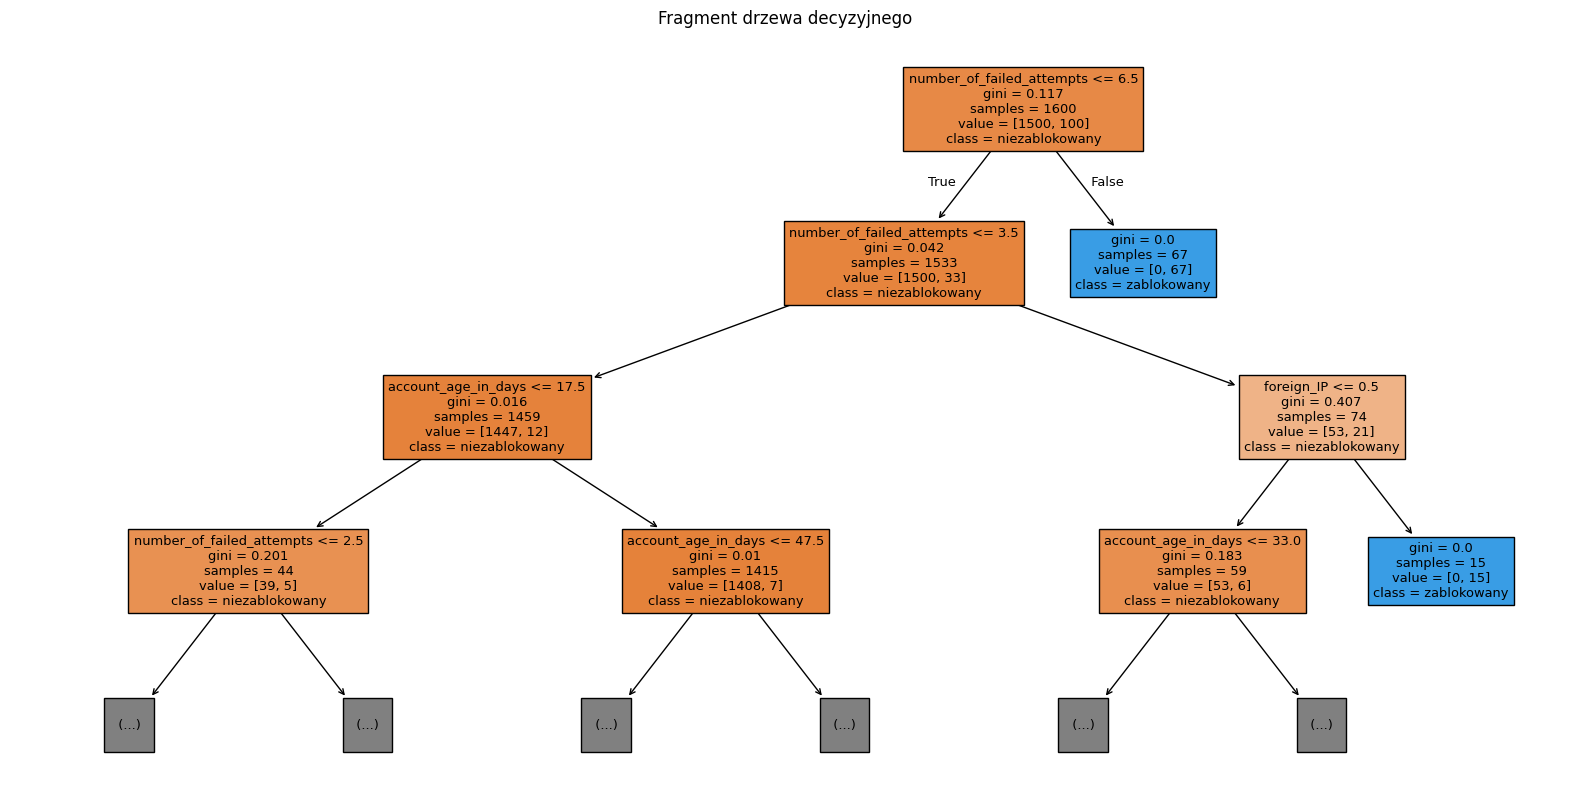

Recall dla pełnego drzewa:       0.80
Recall dla drzewa (max_depth=2): 0.52


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score

# Wczytanie i podział danych 80/20 ze stratyfikacją
dane_logowania = pd.read_csv('login.csv')
cechy_logowania = dane_logowania.drop(columns=['blocked'])
etykiety_blokady = dane_logowania['blocked']

cechy_trening, cechy_test, etykiety_trening, etykiety_test = train_test_split(
    cechy_logowania, etykiety_blokady, test_size=0.2, random_state=42, stratify=etykiety_blokady
)

# Trening pełnego drzewa decyzyjnego i ewaluacja
drzewo_pelne = DecisionTreeClassifier(random_state=42)
drzewo_pelne.fit(cechy_trening, etykiety_trening)
predykcje_pelne = drzewo_pelne.predict(cechy_test)

print("Macierz pomyłek:")
print(confusion_matrix(etykiety_test, predykcje_pelne))
print(f"\nAccuracy:  {accuracy_score(etykiety_test, predykcje_pelne):.2f}")
print(f"Precision: {precision_score(etykiety_test, predykcje_pelne):.2f}")
print(f"Recall:    {recall_score(etykiety_test, predykcje_pelne):.2f}")
print("\nPełny raport klasyfikacji:")
print(classification_report(etykiety_test, predykcje_pelne, target_names=['niezablokowany (0)', 'zablokowany (1)']))

# Wyświetlenie
reguly_tekstowe = export_text(drzewo_pelne, feature_names=list(cechy_logowania.columns))
print("Wyuczone reguły decyzyjne:\n", reguly_tekstowe)

plt.figure(figsize=(20, 10))
plot_tree(drzewo_pelne, feature_names=list(cechy_logowania.columns), class_names=['niezablokowany', 'zablokowany'], filled=True, max_depth=3)
plt.title("Fragment drzewa decyzyjnego")
plt.show()

# Ponowny trening z ograniczeniem głębokości do max_depth=2
drzewo_plytkie = DecisionTreeClassifier(max_depth=2, random_state=42)
drzewo_plytkie.fit(cechy_trening, etykiety_trening)
predykcje_plytkie = drzewo_plytkie.predict(cechy_test)

print(f"Recall dla pełnego drzewa:       {recall_score(etykiety_test, predykcje_pelne):.2f}")
print(f"Recall dla drzewa (max_depth=2): {recall_score(etykiety_test, predykcje_plytkie):.2f}")

Zadanie 2

Odczytaj dane z pliku transakcje.csv i przygotuj dane do trenowania lasów losowych. Po wytrenowaniu modelu przeanalizuj macierz pomyłek. Wyciągnij z wytrenowanego modelu wektor feature_importances_ i stwórz wykres słupkowy pokazujący 3 najważniejsze cechy, którymi kierują się lasy losowe przy wykrywaniu oszustw.

Macierz pomyłek:
[[1990    0]
 [   1    9]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1990
           1       1.00      0.90      0.95        10

    accuracy                           1.00      2000
   macro avg       1.00      0.95      0.97      2000
weighted avg       1.00      1.00      1.00      2000



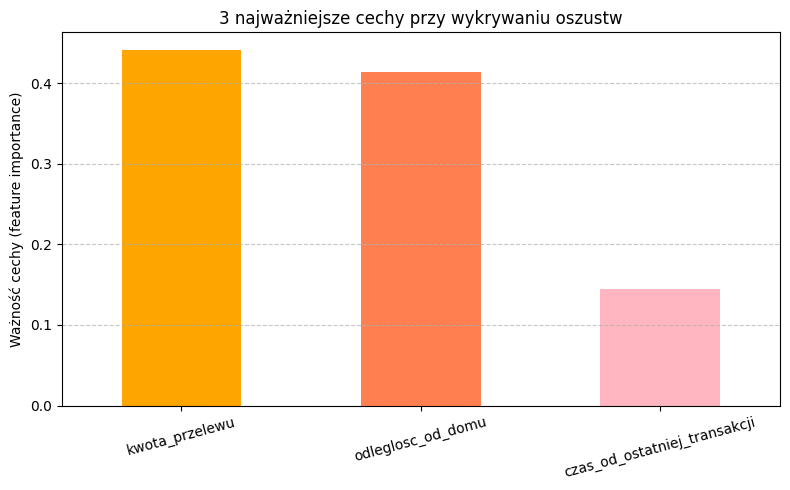

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Wczytanie danych i podział
dane_transakcji = pd.read_csv('transakcje.csv')
cechy_transakcji = dane_transakcji.drop(columns=['is_fraud'])
etykiety_oszustw = dane_transakcji['is_fraud']

cechy_trening, cechy_test, etykiety_trening, etykiety_test = train_test_split(
    cechy_transakcji, etykiety_oszustw, test_size=0.2, random_state=42, stratify=etykiety_oszustw
)

# Trening lasu losowego i ocena na macierzy pomyłek
las_losowy = RandomForestClassifier(random_state=42)
las_losowy.fit(cechy_trening, etykiety_trening)
predykcje_oszustw = las_losowy.predict(cechy_test)

print("Macierz pomyłek:")
print(confusion_matrix(etykiety_test, predykcje_oszustw))
print("\nRaport klasyfikacji:")
print(classification_report(etykiety_test, predykcje_oszustw))

# Wykres ważności cech (feature_importances_)
waznosc_cech = pd.Series(las_losowy.feature_importances_, index=cechy_transakcji.columns)
top_3_cechy = waznosc_cech.sort_values(ascending=False).head(3)

plt.figure(figsize=(8, 5))
top_3_cechy.plot(kind='bar', color=['orange', 'coral', 'lightpink'])
plt.title("3 najważniejsze cechy przy wykrywaniu oszustw")
plt.ylabel("Ważność cechy (feature importance)")
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Zadanie 3


Odczytaj dane ze zbioru SMS Spam Collection Dataset, sprawdź, czy występują braki w kolumnach class lub sms (pozostałe kolumny pomiń). Podziel dane na dwa zbiory: uczący i testowy (80/20). Przy podziale nie zapomnij zastosować stratify. Wytrenuj naiwny klasyfikator Bayesa, a następnie sprawdź jego skuteczność, wyświetlając macierz pomyłek. Spróbuj stworzyć swoje własne wiadomości, aby przetestować działanie klasyfikatora na realnych danych.


Pobranie danych

In [16]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "spam.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "uciml/sms-spam-collection-dataset",
    file_path,
    pandas_kwargs={"encoding": "latin-1"}
)

print("First 5 records:", df.head())

/tmp/ipykernel_6796/3467693523.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.
First 5 records:      v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  


In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix, classification_report

dane_sms = df[['v1', 'v2']].copy()
dane_sms.columns = ['class', 'sms']

print("Liczba brakujących wartości w kolumnach:")
print(dane_sms.isnull().sum())

# Podział na zbiór uczący i testowy (80/20 ze stratyfikacją)
wiadomosci_trening, wiadomosci_test, etykiety_trening, etykiety_test = train_test_split(
    dane_sms['sms'], dane_sms['class'], test_size=0.2, random_state=42, stratify=dane_sms['class']
)

# Zamiana tekstu na macierz zliczeń słów i trening modelu Bayesa
wektoryzator = CountVectorizer()
macierz_trening = wektoryzator.fit_transform(wiadomosci_trening)
macierz_test = wektoryzator.transform(wiadomosci_test)

klasyfikator_bayesa = MultinomialNB()
klasyfikator_bayesa.fit(macierz_trening, etykiety_trening)

# Ewaluacja na zbiorze testowym
predykcje_sms = klasyfikator_bayesa.predict(macierz_test)
print("\nMacierz pomyłek:")
print(confusion_matrix(etykiety_test, predykcje_sms))
print("\nRaport klasyfikacji:")
print(classification_report(etykiety_test, predykcje_sms))

wlasne_wiadomosci = [
    "Ładna dziś pogoda",
    "Pieski są super",
    "Ala ma kota",
    "Kot ma Ale"
]

wektory_wlasne = wektoryzator.transform(wlasne_wiadomosci)
wyniki_wlasne = klasyfikator_bayesa.predict(wektory_wlasne)

print("\nTest na własnych wiadomościach:")
for tekst, wynik in zip(wlasne_wiadomosci, wyniki_wlasne):
    print(f"[{wynik.upper()}] -> {tekst}")

Liczba brakujących wartości w kolumnach:
class    0
sms      0
dtype: int64

Macierz pomyłek:
[[961   5]
 [ 13 136]]

Raport klasyfikacji:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Test na własnych wiadomościach:
[HAM] -> Ładna dziś pogoda
[HAM] -> Pieski są super
[HAM] -> Ala ma kota
[HAM] -> Kot ma Ale
